# Introduction, data sources and exploratory analysis

**Owner: Yuchen Li (z5449540).**

## Motivation and research question
Biomedical papers contain specialised terminology, abbreviations and multiword disease
names. Recognising these mentions supports literature search and indexing.
Our task is to identify the complete span of each disease mention in a PubMed sentence.
For example, the gold annotation of **adenomatous polyposis coli tumour** covers four
words. A prediction ending at **coli** misses the annotated boundary. Disease
abbreviations such as **T-PLL** and **A-T** present another challenge.

We investigate whether biomedical pretraining improves exact-span disease recognition
over general-domain BERT. The group compares BERT, BioBERT and PubMedBERT and tests
additional domain-adaptive pretraining. This part establishes the data source, annotation
quality and corpus characteristics before the modelling sections.

## Setup
Run from the repository root or this notebook's directory. On Colab, the cell clones
the final-submission branch if a checkout is absent. We reuse the shared CoNLL loader
and its pinned SHA-256 checks. Only pandas and matplotlib are needed for this part.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
repository_root = next(
    (p for p in candidates if (p / "ner/data.py").is_file()
     and (p / "parts/manifest.json").is_file()), None
)
if repository_root is None:
    repository_root = Path.cwd() / "bert-ner-final-submission"
    if not repository_root.exists():
        subprocess.check_call([
            "git", "clone", "--branch", "final-submission",
            "https://github.com/lofty14/bert-ner-baseline.git", str(repository_root)
        ])
    if not (repository_root / "ner/data.py").is_file():
        raise RuntimeError("Run inside the final-submission checkout.")
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))
missing = [name for name in ("pandas", "matplotlib")
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

from itertools import combinations
import platform
import pandas as pd
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
from ner.data import load_ncbi, LABELS

print("Python", platform.python_version())
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

Python 3.12.14
pandas 3.0.1 | matplotlib 3.11.2


## Data source and BIO annotation
The **NCBI Disease Corpus** contains 793 PubMed abstract entries annotated for disease
mentions and concept normalisation [1]. We use the sentence-level CoNLL representation
[2]. The task uses disease mention boundaries. Concept linking is outside our evaluation.

Each record contains original tokens and one BIO label per token. An abstract contains
several sentences, and each sentence may contain zero, one or several mentions.

| Label | Meaning |
|---|---|
| O | Outside a disease mention |
| B-Disease | First word of a disease mention |
| I-Disease | Following word within the same mention |

There is one entity type and three token labels. The first training sentence below
shows the original text and the gold annotation defining the disease boundary.

In [2]:
data_splits, data_audit = load_ncbi()
assert all(v["sha256_ok"] and v["orphan_i"] == 0
           for v in data_audit["splits"].values())
assert all(len(tokens) == len(tags) and len(tokens) > 0 and set(tags).issubset(LABELS)
           for rows in data_splits.values() for tokens, tags in rows)
tokens, tags = data_splits["train"][0]
print(" ".join(tokens))
display(pd.DataFrame({"Original token": tokens, "Gold BIO label": tags}))

NCBI Disease CoNLL audit
  train      sentences=5432  tokens=136086 B=5145  I=6122  O=124819 orphan_I=0 dup_in_split=32 sha256=5f87b0de649e... (OK)
  validation sentences=923   tokens=23969  B=787   I=1090  O=22092  orphan_I=0 dup_in_split=0 sha256=b4e1e7efcc2a... (OK)
  test       sentences=940   tokens=24497  B=960   I=1087  O=22450  orphan_I=0 dup_in_split=3 sha256=8f088ce45dc4... (OK)
  cross-split duplicate sentences (unique token sequences): train&validation=5, train&test=1, validation&test=1
Identification of APC2 , a homologue of the adenomatous polyposis coli tumour suppressor .


,Original token,Gold BIO label
0,Identification,O
1,of,O
2,APC2,O
3,",",O
4,a,O
5,homologue,O
6,of,O
7,the,O
8,adenomatous,B-Disease
9,polyposis,I-Disease


## Data integrity and split statistics
Our earlier executed Hugging Face comparison in baseline.ipynb initially returned
5,433/924/941 train/validation/test records. Each split had one trailing empty record.
After filtering these three records, every ordered token sequence and BIO label
sequence matched the CoNLL files exactly.

The saved output below documents that earlier comparison. This notebook's current
execution loads the CoNLL files directly and verifies their hashes above.

**Earlier saved Hugging Face audit output**

```text
train: EXACT MATCH
  Sentences: Hugging Face=5432, CoNLL=5432
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 124819, 'B-Disease': 5145, 'I-Disease': 6122}
  Annotated disease starts (B-Disease): 5145
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9

validation: EXACT MATCH
  Sentences: Hugging Face=923, CoNLL=923
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 22092, 'B-Disease': 787, 'I-Disease': 1090}
  Annotated disease starts (B-Disease): 787
  Orphan I-Disease tags: 0
  CoNLL SHA-256: b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61

test: EXACT MATCH
  Sentences: Hugging Face=940, CoNLL=940
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 22450, 'B-Disease': 960, 'I-Disease': 1087}
  Annotated disease starts (B-Disease): 960
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 8f088ce45dc4746592188f9e69de3d89d87f3bb8f0ed8c4a287d018123fa148d
```

In [3]:
split_summary = pd.DataFrame.from_dict({
    split: {"Sentences": v["sentences"], "Original tokens": v["tokens"],
            "Disease mentions": v["entities"], "Orphan I tags": v["orphan_i"]}
    for split, v in data_audit["splits"].items()
}, orient="index")
display(split_summary)
for split, result in data_audit["splits"].items():
    print(split, "SHA-256", result["sha256"])

,Sentences,Original tokens,Disease mentions,Orphan I tags
train,5432,136086,5145,0
validation,923,23969,787,0
test,940,24497,960,0


train SHA-256 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9
validation SHA-256 b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61
test SHA-256 8f088ce45dc4746592188f9e69de3d89d87f3bb8f0ed8c4a287d018123fa148d


### Split sizes
The original split assignments are retained. The training split updates model weights,
validation supports experimental decisions, and test measures final performance.
Removing empty records preserves all annotated words and mentions.

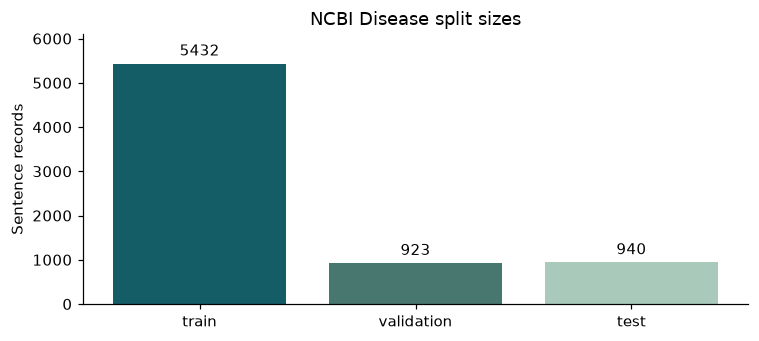

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(split_summary.index, split_summary["Sentences"],
              color=["#145D67", "#47776E", "#A9CABB"])
ax.bar_label(bars, fmt="%d", padding=3)
ax.set(ylabel="Sentence records", title="NCBI Disease split sizes", ylim=(0, 6100))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Exploratory data analysis
### BIO label distribution
B-Disease starts count mentions. I-Disease counts subsequent words within mentions.
The following distribution is measured at the original-word level. The large
O proportion motivates reporting entity-level precision, recall and F1 alongside
word-level accuracy, which can conceal missed disease mentions.

,O,B-Disease,I-Disease
train,124819,5145,6122
validation,22092,787,1090
test,22450,960,1087


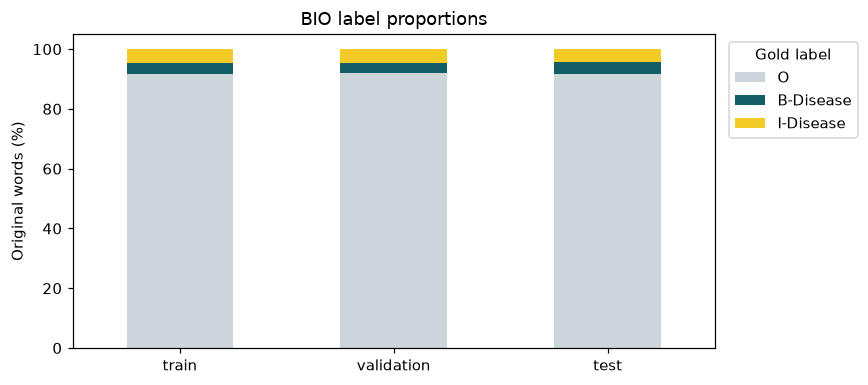

In [5]:
label_counts = pd.DataFrame({
    split: v["tag_counts"] for split, v in data_audit["splits"].items()
}).T.reindex(columns=LABELS)
display(label_counts)
label_percent = label_counts.div(label_counts.sum(axis=1), axis=0) * 100
ax = label_percent.plot.bar(
    stacked=True, color=["#CBD5DA", "#145D67", "#F3CB27"],
    figsize=(8, 3.6), rot=0)
ax.set(ylabel="Original words (%)", xlabel="", title="BIO label proportions")
ax.legend(title="Gold label", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Disease mention lengths
A mention begins at B-Disease and includes following I-Disease words until an O,
another B-Disease, or the sentence end. Adjacent mentions are counted separately.
Lengths are measured in original words before subword tokenization.

,1 word,2 words,3 words,4+ words,Total
train,2266,1402,643,834,5145
validation,283,225,122,157,787
test,423,270,133,134,960


,Multiword mentions (%)
train,56.0
validation,64.0
test,55.9


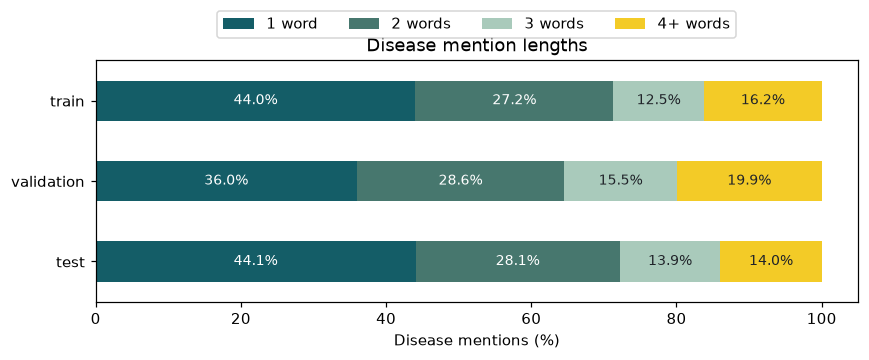

In [6]:
def disease_mention_lengths(tags):
    lengths = []
    current_length = 0
    for tag in [*tags, "O"]:
        if tag == "I-Disease":
            assert current_length > 0, "Orphan I-Disease tag"
            current_length += 1
        else:
            if current_length:
                lengths.append(current_length)
            current_length = 1 if tag == "B-Disease" else 0
    return lengths

mention_lengths = {
    split: [length for _, tags in rows for length in disease_mention_lengths(tags)]
    for split, rows in data_splits.items()
}
mention_table = pd.DataFrame.from_dict({
    split: {"1 word": sum(n == 1 for n in lengths),
            "2 words": sum(n == 2 for n in lengths),
            "3 words": sum(n == 3 for n in lengths),
            "4+ words": sum(n >= 4 for n in lengths)}
    for split, lengths in mention_lengths.items()
}, orient="index")
assert mention_table.sum(axis=1).equals(split_summary["Disease mentions"])
display(mention_table.assign(Total=mention_table.sum(axis=1)))
mention_percent = mention_table.div(mention_table.sum(axis=1), axis=0) * 100
display((100 - mention_percent["1 word"]).round(1).to_frame("Multiword mentions (%)"))
ax = mention_percent.plot.barh(
    stacked=True, color=["#145D67", "#47776E", "#A9CABB", "#F3CB27"],
    figsize=(8, 3.4))
ax.set(xlabel="Disease mentions (%)", ylabel="", title="Disease mention lengths")
ax.invert_yaxis()
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.06))
for i, container in enumerate(ax.containers):
    ax.bar_label(container, fmt="%.1f%%", label_type="center",
                 color="white" if i < 2 else "#202329", fontsize=9)
plt.tight_layout()
plt.show()

Multiword mentions comprise **56.0% of train**, **64.0% of validation**, and
**55.9% of test** mentions. Complete boundaries therefore matter for most mentions.
Validation has a somewhat higher multiword share. These plots describe corpus
properties. Model performance by mention length would require predictions as well.

### Sentence lengths
The next plot compares original-word sentence lengths using common histogram bins.
The model's 512-position limit applies after subword tokenization and special tokens.

,count,mean,50%,95%,max
train,5432.0,25.05,23.0,48.0,123.0
validation,923.0,25.97,24.0,47.0,86.0
test,940.0,26.06,24.0,49.0,106.0


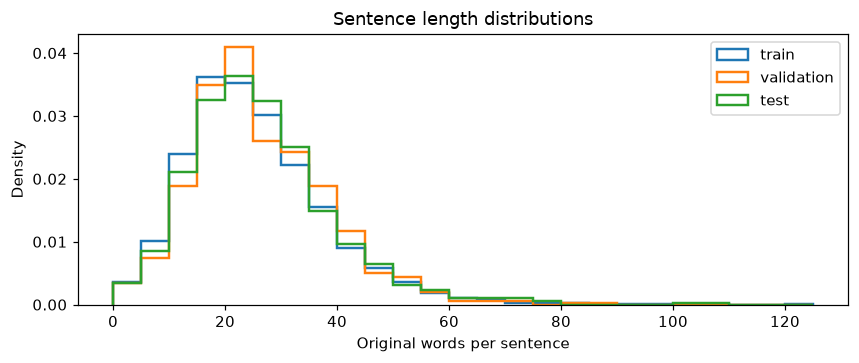

In [7]:
sentence_lengths = {
    split: pd.Series([len(tokens) for tokens, _ in rows], dtype="int64")
    for split, rows in data_splits.items()
}
display(pd.DataFrame({
    split: values.describe(percentiles=[0.5, 0.95])
    for split, values in sentence_lengths.items()
}).T[["count", "mean", "50%", "95%", "max"]].round(2))
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = range(0, max(int(v.max()) for v in sentence_lengths.values()) + 6, 5)
for split, values in sentence_lengths.items():
    ax.hist(values, bins=bins, histtype="step", density=True, linewidth=1.6, label=split)
ax.set(xlabel="Original words per sentence", ylabel="Density",
       title="Sentence length distributions")
ax.legend()
fig.tight_layout()
plt.show()

### Repeated sentence sequences
The shared audit counts identical original-token sequences within and across splits.
We retain the supplied split assignments and disclose these overlaps when interpreting
generalisation. Short generic sentences can repeat, so identical sentence sequences
alone do not establish duplication of complete abstracts.

In [8]:
display(pd.DataFrame.from_dict({
    split: {"Additional repeated sentence records":
            v["within_split_duplicate_sentences"]}
    for split, v in data_audit["splits"].items()
}, orient="index"))
sentence_sets = {split: {tuple(tokens) for tokens, _ in rows}
                 for split, rows in data_splits.items()}
for first, second in combinations(sentence_sets, 2):
    overlaps = sorted(sentence_sets[first] & sentence_sets[second])
    print(f"{first} / {second}: {len(overlaps)} shared unique token sequences")
    for tokens in overlaps:
        print("  ", " ".join(tokens))

,Additional repeated sentence records
train,32
validation,0
test,3


train / validation: 5 shared unique token sequences
   1 1 .
   2 2 .
   3 .
   METHODS .
   RESULTS .
train / test: 1 shared unique token sequences
   Hereditary deficiency of the fifth component of complement in man .
validation / test: 1 shared unique token sequences
   5 of embryogenesis .


## Tokenization and label alignment
Earlier executed checks in baseline.ipynb measured complete input lengths with
truncation disabled, including special tokens. These prior measurements are recorded
here for provenance, rather than presented as new tokenizer runs.

| Tokenizer | Max train | Max validation | Max test | Above 512 |
|---|---:|---:|---:|---:|
| BERT, bert-base-cased | 178 | 122 | 157 | 0 |
| BioBERT v1.2, cased | 178 | 122 | 157 | 0 |
| PubMedBERT, abstracts-only uncased | 139 | 95 | 130 | 0 |

All checked sequences fit within 512 positions. These tokenizer lengths alone do not
explain differences in model F1.

The preprocessing keeps the gold BIO label only on each original word's first
subword. Subsequent subwords and special tokens receive **−100** and are ignored in
loss and metric calculations. The earlier alignment inspection showed
**ad → B-Disease** followed by **##eno, ##mat, ##ous → IGNORE**.
The model parts implement this alignment with each matching tokenizer.

## Implications for the experiments
The data contains one disease entity type and a large proportion of O labels.
Entity-level scoring evaluates complete spans and complements word-level accuracy.
Multiword names and abbreviations motivate the boundary and missed-entity analyses.
File hashes and ordered source comparisons document the annotations used.
The next parts explain the models, fine-tuning and evaluation protocols.

## References
1. R. I. Doğan, R. Leaman and Z. Lu (2014). NCBI disease corpus: a resource for disease
   name recognition and concept normalization. Journal of Biomedical Informatics, 47,
   1–10. https://doi.org/10.1016/j.jbi.2013.12.006
2. S. Pyysalo. NCBI Disease Corpus, CoNLL-format files.
   https://github.com/spyysalo/ncbi-disease/tree/master/conll
3. Group repository, earlier executed baseline.ipynb, including the Hugging Face audit,
   tokenizer lengths and label-alignment inspection.
   https://github.com/lofty14/bert-ner-baseline